# MAAI901 Individual Project Notebook - Comparing MobileNetV3 and MobileViT-XSS against increasing levels of image corruption on the EuroSAT dataset
NAME - Vinayak Parayil Nair

STUDENT ID - 1681692

## Environment and GPU
Checking the environment and GPU (NVIDIA L4 GPU) for the project.

In [ ]:

import os
import subprocess
import torch

# Checking whether the notebook is running in Google Colab
IN_COLAB = "google.colab" in str(os.environ.get("COLAB_RELEASE_TAG", ""))

print("=" * 60)
print("ENVIRONMENT VERIFICATION")
print("=" * 60)

print(f"Running in Google Colab: {IN_COLAB}")
print(f"PyTorch version: {torch.__version__}")
print(f"PyTorch CUDA build: {torch.version.cuda}")
print(f"CUDA available to PyTorch: {torch.cuda.is_available()}")

# Checking GPU hardware
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. No GPU is accessible to PyTorch. "
        "In Colab, select Runtime > Change runtime type > GPU, "
        "then reconnect and rerun this cell."
    )

gpu_name = torch.cuda.get_device_name(0)
gpu_properties = torch.cuda.get_device_properties(0)

total_memory_gb = gpu_properties.total_memory / (1024 ** 3)

print("\n" + "=" * 60)
print("GPU DETAILS")
print("=" * 60)

print(f"GPU name: {gpu_name}")
print(f"Total GPU memory: {total_memory_gb:.2f} GB")
print(f"CUDA device count: {torch.cuda.device_count()}")

# Displaying NVIDIA driver and current GPU utilisation/memory
try:
    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,memory.used,memory.free",
            "--format=csv"
        ],
        capture_output=True,
        text=True,
        check=True
    )

    print("\nNVIDIA GPU STATUS:")
    print(result.stdout)

except (FileNotFoundError, subprocess.CalledProcessError):
    print("\nCould not retrieve additional information using nvidia-smi.")

# Verifying the intended hardware
if "L4" not in gpu_name.upper():
    raise RuntimeError(
        f"Expected an NVIDIA L4 GPU, but detected: {gpu_name}\n"
        "Stop here. Do not install packages or begin training yet. "
        "Check the selected Colab accelerator and rerun this cell."
    )

# Performing a small CUDA computation
test_tensor = torch.randn(1024, 1024, device="cuda")
test_result = test_tensor @ test_tensor

torch.cuda.synchronize()

print("\n" + "=" * 60)
print("CUDA FUNCTIONALITY TEST")
print("=" * 60)

print(f"Test tensor device: {test_tensor.device}")
print(f"Test result shape: {tuple(test_result.shape)}")
print(f"CUDA computation successful: {test_result.is_cuda}")

# Cleaning up temporary test tensors
del test_tensor, test_result
torch.cuda.empty_cache()

print("\nSUCCESS: NVIDIA L4 detected and CUDA computation verified.")
print("You may proceed to the next notebook cell.")

ENVIRONMENT VERIFICATION
Running in Google Colab: False
PyTorch version: 2.11.0+cu130
PyTorch CUDA build: 13.0
CUDA available to PyTorch: True

GPU DETAILS
GPU name: NVIDIA L4
Total GPU memory: 22.03 GB
CUDA device count: 1

NVIDIA GPU STATUS:
name, memory.total [MiB], memory.used [MiB], memory.free [MiB]
NVIDIA L4, 23034 MiB, 3 MiB, 22561 MiB


CUDA FUNCTIONALITY TEST
Test tensor device: cuda:0
Test result shape: (1024, 1024)
CUDA computation successful: True

SUCCESS: NVIDIA L4 detected and CUDA computation verified.
You may proceed to the next notebook cell.


## Libraries and Configurations

Importing libraries and setting up configurations for the experiment like fixed random seed for reproducibility, and viewing our environment's specifications.

In [ ]:
import os
import sys
import random
import platform
import json
import time
import copy
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms, datasets, models
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from pathlib import Path

# Reproducibility

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Hardware configuration
DEVICE = torch.device("cuda:0")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Stop before proceeding.")

GPU_NAME = torch.cuda.get_device_name(0)

if "L4" not in GPU_NAME.upper():
    raise RuntimeError(
        f"Expected NVIDIA L4, but detected {GPU_NAME}. "
        "Stop before proceeding."
    )

# Project configuration
PROJECT_NAME = "EuroSAT_Robustness_Efficiency"
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2


OUTPUT_DIR = Path("/content") / PROJECT_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Performance settings
torch.backends.cudnn.benchmark = True

# Display environment details
print("=" * 60)
print("EXPERIMENT CONFIGURATION")
print("=" * 60)

print(f"Python version: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"CUDA version used by PyTorch: {torch.version.cuda}")
print(f"GPU: {GPU_NAME}")
print(f"Device: {DEVICE}")
print(f"Random seed: {SEED}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Model input size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Data loader workers: {NUM_WORKERS}")
print(f"Output directory: {OUTPUT_DIR}")

print("\nAll imports and configuration completed successfully.")

EXPERIMENT CONFIGURATION
Python version: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
NumPy version: 2.1.3
Pandas version: 2.2.3
CUDA version used by PyTorch: 13.0
GPU: NVIDIA L4
Device: cuda:0
Random seed: 42
Number of classes: 10
Model input size: 224 x 224
Batch size: 64
Data loader workers: 2
Output directory: /content/EuroSAT_Robustness_Efficiency

All imports and configuration completed successfully.


## The Dataset and EDA
In the code block below, we are downloading the EuroSAT RGB dataset using 'torchvision' and doing some exploratory data analysis (EDA).

The first download may take a few minutes.


100%|██████████| 94.3M/94.3M [00:01<00:00, 86.8MB/s]



DATASET SUMMARY
Total images: 27,000
Number of classes: 10
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Class-to-index mapping: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

Class distribution:


,Class,Class_Index,Image_Count
0,AnnualCrop,0,3000
1,Forest,1,3000
2,HerbaceousVegetation,2,3000
3,Highway,3,2500
4,Industrial,4,2500
5,Pasture,5,2000
6,PermanentCrop,6,2500
7,Residential,7,3000
8,River,8,2500
9,SeaLake,9,3000



Sample image properties:
Index:     0 | Class: AnnualCrop           | Size: (64, 64) | Mode: RGB | Format: None
Index:  9000 | Class: Highway              | Size: (64, 64) | Mode: RGB | Format: None
Index: 18000 | Class: PermanentCrop        | Size: (64, 64) | Mode: RGB | Format: None
Index: 26999 | Class: SeaLake              | Size: (64, 64) | Mode: RGB | Format: None


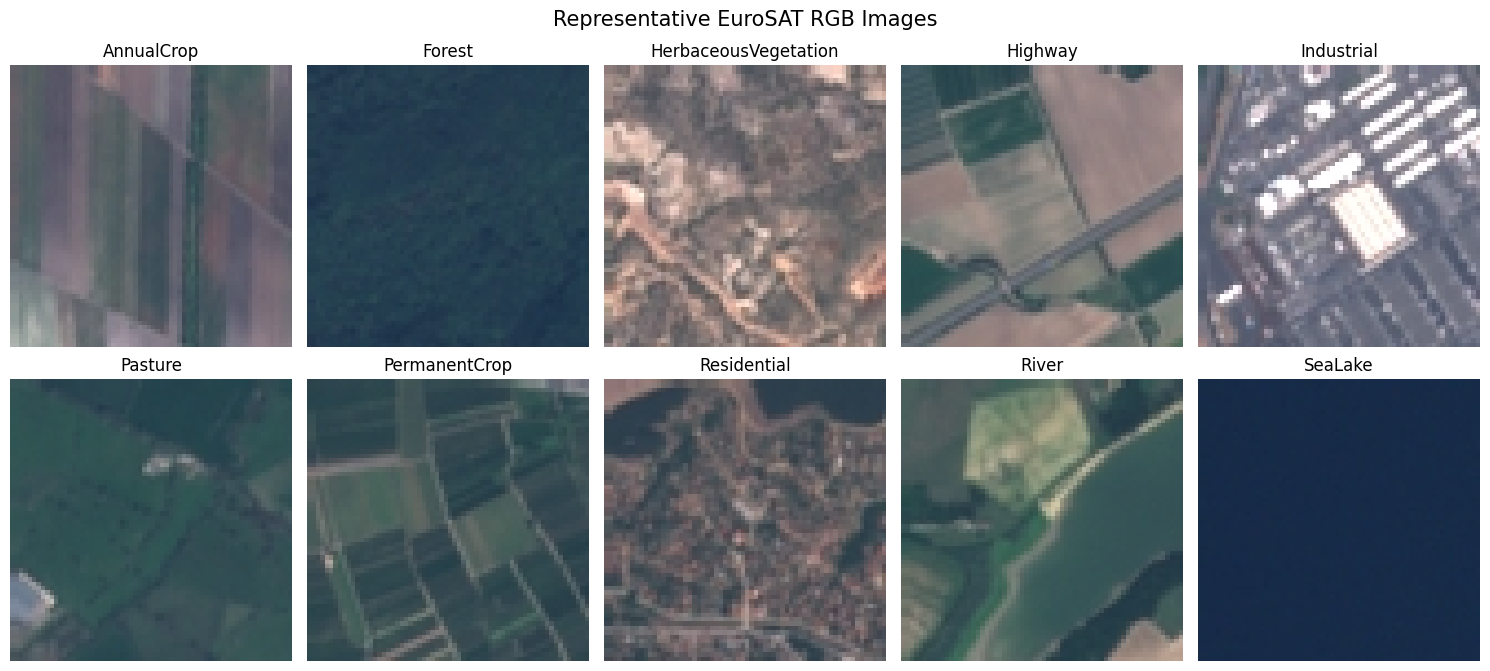


IMAGE VALIDATION
Image dimensions and counts: Counter({(64, 64): 27000})
Image modes and counts: Counter({'RGB': 27000})
Invalid image objects: 0

Inspection outputs saved to: /content/EuroSAT_Robustness_Efficiency
Dataset download and inspection completed.


In [ ]:

from torchvision.datasets import EuroSAT
from collections import Counter
from PIL import Image, UnidentifiedImageError

DATA_DIR = Path("/content/eurosat_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Downloading or loading EuroSAT RGB dataset...")
print("The first download may take a few minutes.")

try:
    dataset = EuroSAT(
        root=str(DATA_DIR),
        download=True,
        transform=None
    )
except Exception as e:
    raise RuntimeError(
        "EuroSAT download or loading failed. "
        "Please share the complete error before trying another method."
    ) from e

# ------------------------------------------------------------
# 1. Dataset size and class names
# ------------------------------------------------------------
class_names = dataset.classes
class_to_idx = dataset.class_to_idx
targets = np.array(dataset.targets)

print("\n" + "=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(f"Total images: {len(dataset):,}")
print(f"Number of classes: {len(class_names)}")
print(f"Class names: {class_names}")
print(f"Class-to-index mapping: {class_to_idx}")

if len(class_names) != NUM_CLASSES:
    raise ValueError(
        f"Expected {NUM_CLASSES} classes, found {len(class_names)}."
    )

# ------------------------------------------------------------
# 2. Class distribution
# ------------------------------------------------------------
class_counts = Counter(targets.tolist())

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Class_Index": [class_to_idx[name] for name in class_names],
    "Image_Count": [
        class_counts[class_to_idx[name]]
        for name in class_names
    ]
})

print("\nClass distribution:")
display(class_distribution)

# ------------------------------------------------------------
# 3. Inspect sample images and image properties
# ------------------------------------------------------------
sample_indices = [
    0,
    len(dataset) // 3,
    2 * len(dataset) // 3,
    len(dataset) - 1
]

print("\nSample image properties:")

for idx in sample_indices:
    image, label = dataset[idx]

    print(
        f"Index: {idx:5d} | "
        f"Class: {class_names[label]:20s} | "
        f"Size: {image.size} | "
        f"Mode: {image.mode} | "
        f"Format: {image.format}"
    )

# ------------------------------------------------------------
# 4. Visualise representative images
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

# Use a seeded random generator for reproducible examples.
rng = np.random.default_rng(SEED)

for class_idx, ax in enumerate(axes):
    indices = np.flatnonzero(targets == class_idx)
    idx = int(rng.choice(indices))

    image, label = dataset[idx]

    ax.imshow(image)
    ax.set_title(class_names[label].replace("_", " "))
    ax.axis("off")

plt.suptitle("Representative EuroSAT RGB Images", fontsize=15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Verify image dimensions and channels across the dataset
# ------------------------------------------------------------
image_sizes = Counter()
image_modes = Counter()
corrupt_files = []

for idx, (image, label) in enumerate(dataset):
    if not isinstance(image, Image.Image):
        corrupt_files.append(idx)
        continue

    image_sizes[image.size] += 1
    image_modes[image.mode] += 1

print("\n" + "=" * 60)
print("IMAGE VALIDATION")
print("=" * 60)

print(f"Image dimensions and counts: {image_sizes}")
print(f"Image modes and counts: {image_modes}")
print(f"Invalid image objects: {len(corrupt_files)}")

if corrupt_files:
    raise RuntimeError(
        f"Invalid image objects found at dataset indices: "
        f"{corrupt_files[:10]}"
    )

if len(image_sizes) != 1:
    print("WARNING: More than one image size was found.")

if any(mode != "RGB" for mode in image_modes):
    print("WARNING: Some images are not RGB.")

# ------------------------------------------------------------
# 6. Save dataset inspection outputs
# ------------------------------------------------------------
class_distribution.to_csv(
    OUTPUT_DIR / "eurosat_class_distribution.csv",
    index=False
)

dataset_summary = {
    "dataset": "EuroSAT RGB",
    "total_images": len(dataset),
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "image_sizes": {
        str(size): count for size, count in image_sizes.items()
    },
    "image_modes": dict(image_modes),
    "random_seed": SEED
}

with open(OUTPUT_DIR / "dataset_summary.json", "w") as f:
    json.dump(dataset_summary, f, indent=2)

print(f"\nInspection outputs saved to: {OUTPUT_DIR}")
print("Dataset download and inspection completed.")

As we can see, the EDA shows us that the dataset consists of 27000 RGB images (64x64) labelled into 10 classes.

The dataset is not completely balanced, some classes have 2000-2500 images, while others have 3000 images.

## Dataset Split
Due to the datasets imbalance, during the spliting of the dataet into train, validation and test splits, we can use stratification to approximate class proportions in each split.


The split ratio used - 70% training, 15% validation, 15% test

Both the model will use the same splits.

In [ ]:
# First split: 70% training, 30% temporary
all_indices = np.arange(len(dataset))

train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

# Second split: divide temporary set equally into validation and test
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_indices]
)

# ------------------------------------------------------------
# Verify sizes and no overlap
# ------------------------------------------------------------
assert len(train_indices) + len(val_indices) + len(test_indices) == len(dataset)

assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0

assert len(set(train_indices) | set(val_indices) | set(test_indices)) == len(dataset)

print("=" * 60)
print("DATASET SPLIT SUMMARY")
print("=" * 60)

print(f"Training images:   {len(train_indices):,} ({len(train_indices)/len(dataset):.1%})")
print(f"Validation images: {len(val_indices):,} ({len(val_indices)/len(dataset):.1%})")
print(f"Test images:       {len(test_indices):,} ({len(test_indices)/len(dataset):.1%})")
print(f"Total images:      {len(dataset):,}")

print("\nNo overlap between splits: verified.")
print("Every dataset index is assigned to exactly one split.")

# ------------------------------------------------------------
# Check per-class distribution
# ------------------------------------------------------------
def get_split_counts(indices, split_name):
    split_targets = targets[indices]
    counts = Counter(split_targets.tolist())

    return {
        "Class": class_names,
        f"{split_name}_Count": [
            counts.get(class_to_idx[name], 0)
            for name in class_names
        ]
    }

split_distribution = pd.DataFrame({"Class": class_names})

for indices, split_name in [
    (train_indices, "Train"),
    (val_indices, "Validation"),
    (test_indices, "Test")
]:
    split_counts = get_split_counts(indices, split_name)
    split_distribution[f"{split_name}_Count"] = split_counts[f"{split_name}_Count"]

print("\nPer-class split distribution:")
display(split_distribution)

# ------------------------------------------------------------
# Persist split indices and metadata
# ------------------------------------------------------------
split_path = OUTPUT_DIR / "eurosat_split_indices.npz"

np.savez(
    split_path,
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices
)

split_metadata = {
    "seed": SEED,
    "train_fraction": 0.70,
    "validation_fraction": 0.15,
    "test_fraction": 0.15,
    "train_count": len(train_indices),
    "validation_count": len(val_indices),
    "test_count": len(test_indices),
    "class_names": class_names
}

with open(OUTPUT_DIR / "split_metadata.json", "w") as f:
    json.dump(split_metadata, f, indent=2)

split_distribution.to_csv(
    OUTPUT_DIR / "eurosat_split_distribution.csv",
    index=False
)

print(f"\nSplit indices saved to: {split_path}")
print("Split metadata and class counts saved.")

DATASET SPLIT SUMMARY
Training images:   18,900 (70.0%)
Validation images: 4,050 (15.0%)
Test images:       4,050 (15.0%)
Total images:      27,000

No overlap between splits: verified.
Every dataset index is assigned to exactly one split.

Per-class split distribution:


,Class,Train_Count,Validation_Count,Test_Count
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450



Split indices saved to: /content/EuroSAT_Robustness_Efficiency/eurosat_split_indices.npz
Split metadata and class counts saved.


## Image Preprocessing
- Images get resized to 224x224, to suit the selected architectures' needs.
- Images converted to tensors with PyTorch
- ImageNet normalization applid to the images
- Configuring data loaders to load the splits, while keeping the validation and test splits deterministic.

In [ ]:

from torch.utils.data import Subset, DataLoader
from torchvision import transforms

# ImageNet normalization
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Deterministic preprocessing
base_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Apply the same preprocessing convention to all subsets.
dataset.transform = base_transform

# Create subsets using the existing split indices.
train_dataset = Subset(dataset, train_indices.tolist())
val_dataset = Subset(dataset, val_indices.tolist())
test_dataset = Subset(dataset, test_indices.tolist())

# Configure data loaders.
# Training shuffles sample order; validation and test do not.
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    generator=train_generator,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

# ------------------------------------------------------------
# Inspect one batch
# ------------------------------------------------------------
images, labels = next(iter(train_loader))

print("=" * 60)
print("DATA LOADER VERIFICATION")
print("=" * 60)

print(f"Training subset size: {len(train_dataset):,}")
print(f"Validation subset size: {len(val_dataset):,}")
print(f"Test subset size: {len(test_dataset):,}")

print(f"\nTraining batch shape: {tuple(images.shape)}")
print(f"Training labels shape: {tuple(labels.shape)}")
print(f"Image tensor dtype: {images.dtype}")
print(f"Label tensor dtype: {labels.dtype}")
print(f"Image tensor device before transfer: {images.device}")

print(f"\nBatch pixel-value range after normalization: "
      f"{images.min().item():.3f} to {images.max().item():.3f}")

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.ndim == 1
assert labels.min().item() >= 0
assert labels.max().item() < NUM_CLASSES

print("\nData loaders created and verified successfully.")

DATA LOADER VERIFICATION
Training subset size: 18,900
Validation subset size: 4,050
Test subset size: 4,050

Training batch shape: (64, 3, 224, 224)
Training labels shape: (64,)
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
Image tensor device before transfer: cpu

Batch pixel-value range after normalization: -1.758 to 2.640

Data loaders created and verified successfully.


## Loading MobileNetV3-Small
In the code block below, we will be loading and verifying the MobileNetV3-Small architecture with pretrained ImageNet weights, after which the original classification head will be replaced with an output layer of 10 classes.

In [ ]:

from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

print("Loading MobileNetV3-Small with pretrained ImageNet weights...")

try:
    mobilenet_weights = MobileNet_V3_Small_Weights.DEFAULT

    mobilenet_model = mobilenet_v3_small(
        weights=mobilenet_weights
    )

    print("Pretrained MobileNetV3-Small loaded successfully.")

except Exception as e:
    raise RuntimeError(
        "Could not load pretrained MobileNetV3-Small. "
        "Share the complete error before proceeding."
    ) from e

# Inspect the original classifier.
print("\nOriginal classifier:")
print(mobilenet_model.classifier)

# Replace the final classification layer with a 10-class layer.
in_features = mobilenet_model.classifier[-1].in_features

mobilenet_model.classifier[-1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

# Move the model to the verified L4 GPU.
mobilenet_model = mobilenet_model.to(DEVICE)

# Run a small forward-pass test.
mobilenet_model.eval()

with torch.inference_mode():
    test_batch = images[:4].to(DEVICE)
    test_logits = mobilenet_model(test_batch)

torch.cuda.synchronize()

print("\n" + "=" * 60)
print("MOBILENETV3-SMALL VERIFICATION")
print("=" * 60)

print(f"Model: MobileNetV3-Small")
print(f"Device: {next(mobilenet_model.parameters()).device}")
print(f"Output shape: {tuple(test_logits.shape)}")
print(f"Expected output shape: (4, {NUM_CLASSES})")
print(f"Total parameters: {sum(p.numel() for p in mobilenet_model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in mobilenet_model.parameters() if p.requires_grad):,}")

assert test_logits.shape == (4, NUM_CLASSES)

print("\nMobileNetV3-Small passed the forward-pass test.")

Loading MobileNetV3-Small with pretrained ImageNet weights...
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 176MB/s]


Pretrained MobileNetV3-Small loaded successfully.

Original classifier:
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)

MOBILENETV3-SMALL VERIFICATION
Model: MobileNetV3-Small
Device: cuda:0
Output shape: (4, 10)
Expected output shape: (4, 10)
Total parameters: 1,528,106
Trainable parameters: 1,528,106

MobileNetV3-Small passed the forward-pass test.


## Verifying MobileViT-XXS Availability

In [ ]:

import importlib.util

print("=" * 60)
print("MOBILEVIT-XXS DEPENDENCY CHECK")
print("=" * 60)

timm_available = importlib.util.find_spec("timm") is not None

print(f"timm installed: {timm_available}")

if timm_available:
    import timm

    print(f"timm version: {timm.__version__}")

    matching_models = [
        name for name in timm.list_models("*mobilevit*")
        if "xxs" in name.lower()
    ]

    print("\nMobileViT-XXS model names registered in timm:")
    for name in matching_models:
        print(f"  - {name}")

    if not matching_models:
        print(
            "\nNo MobileViT-XXS model name was found in this "
            "installation of timm."
        )
else:
    print(
        "\ntimm is not installed. No packages have been changed. "
        "We will choose a compatible implementation based on this result."
    )

MOBILEVIT-XXS DEPENDENCY CHECK
timm installed: True
timm version: 1.0.30

MobileViT-XXS model names registered in timm:
  - mobilevit_xxs


## Loading MobileViT-XXS
Since confirmed the availability of MobileViT-XXS in the above code block, we will now :
- load the model with its pretrained ImageNet weights,
- replace the classification head to predict our 10 EuroSAT classes.

In [ ]:

import timm
import torch.nn as nn

print("=" * 60)
print("LOADING MOBILViT-XXS")
print("=" * 60)

mobilevit_model = timm.create_model(
    "mobilevit_xxs",
    pretrained=True,
    num_classes=NUM_CLASSES
)

mobilevit_model = mobilevit_model.to(DEVICE)
mobilevit_model.eval()

# Verify the forward pass using a batch from the existing data loader
with torch.no_grad():
    sample_images, sample_labels = next(iter(train_loader))
    sample_images = sample_images[:4].to(DEVICE)
    sample_outputs = mobilevit_model(sample_images)

total_params = sum(p.numel() for p in mobilevit_model.parameters())
trainable_params = sum(
    p.numel() for p in mobilevit_model.parameters() if p.requires_grad
)

print(f"Model: MobileViT-XXS")
print(f"Device: {DEVICE}")
print(f"Output shape: {tuple(sample_outputs.shape)}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Expected output shape: (4, {NUM_CLASSES})")

assert sample_outputs.shape == (4, NUM_CLASSES), (
    f"Unexpected output shape: {sample_outputs.shape}"
)

print("\nMobileViT-XXS verification successful.")


LOADING MOBILViT-XXS


model.safetensors: reconstructing file:   0%|          |  0.00B / 5.14MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: MobileViT-XXS
Device: cuda:0
Output shape: (4, 10)
Total parameters: 954,234
Trainable parameters: 954,234
Expected output shape: (4, 10)

MobileViT-XXS verification successful.


From loading the two models we can see that the MobileViT-XXS has 954234 parameters ,which is fewer than MobileNetV3-Small's 1528106 parameters.

## Setting Up Google Drive
In the code below, we will mount Google Drive and create a dedicated project directory where we will save checkpoints, split files, and results, to ensure we dont lose the progress made during runs.

In [ ]:

from google.colab import drive
import os
import shutil

# Mount Google Drive (Colab may ask you to authorize access)
drive.mount("/content/drive")

# Persistent project directory
DRIVE_OUTPUT_DIR = (
    "/content/drive/MyDrive/EuroSAT_Robustness_Efficiency"
)
os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)

# Preserve artifacts already generated in this session
copied_files = []

for filename in os.listdir(OUTPUT_DIR):
    source_path = os.path.join(OUTPUT_DIR, filename)
    destination_path = os.path.join(DRIVE_OUTPUT_DIR, filename)

    if os.path.isfile(source_path):
        shutil.copy2(source_path, destination_path)
        copied_files.append(filename)

print("=" * 60)
print("PERSISTENT STORAGE READY")
print("=" * 60)
print(f"Drive directory: {DRIVE_OUTPUT_DIR}")
print(f"Existing files copied: {len(copied_files)}")

for filename in copied_files:
    print(f"  - {filename}")

print("\nBoth models remain loaded in the current runtime.")


Mounted at /content/drive
PERSISTENT STORAGE READY
Drive directory: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency
Existing files copied: 5
  - eurosat_split_distribution.csv
  - eurosat_split_indices.npz
  - eurosat_class_distribution.csv
  - split_metadata.json
  - dataset_summary.json

Both models remain loaded in the current runtime.


## Training Configuration
Setting upp training configuration consisting of:
- 5 epochs
- 1e-3 learning decay
- 1e-4 weight decay
- cross entropy loss
- AdamW optimization

In [ ]:

import json
import time
import copy
import torch
import torch.nn as nn

# Shared training configuration
TRAIN_CONFIG = {
    "seed": SEED,
    "device": str(DEVICE),
    "epochs": 5,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "batch_size": BATCH_SIZE,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "models": ["MobileNetV3-Small", "MobileViT-XXS"],
    "selection_metric": "validation_accuracy",
    "early_stopping_patience": 2,
    "test_split_used_during_training": False,
}

# Save experiment configuration to persistent storage
config_path = os.path.join(DRIVE_OUTPUT_DIR, "training_config.json")
with open(config_path, "w") as f:
    json.dump(TRAIN_CONFIG, f, indent=2)

# Set random seeds for reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Set up loss function
criterion = nn.CrossEntropyLoss()

print("=" * 60)
print("TRAINING CONFIGURATION")
print("=" * 60)
for key, value in TRAIN_CONFIG.items():
    print(f"{key}: {value}")

print(f"\nConfiguration saved to: {config_path}")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated(0) / 1e9:.2f} GB")


TRAINING CONFIGURATION
seed: 42
device: cuda:0
epochs: 5
learning_rate: 0.001
weight_decay: 0.0001
optimizer: AdamW
loss: CrossEntropyLoss
batch_size: 64
image_size: 224
num_classes: 10
models: ['MobileNetV3-Small', 'MobileViT-XXS']
selection_metric: validation_accuracy
early_stopping_patience: 2
test_split_used_during_training: False

Configuration saved to: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/training_config.json
GPU: NVIDIA L4
GPU memory allocated: 0.02 GB


## Estimating Training Speed
The Training Speed Pilot in the below code is used to benchmark the two architectures using forward and backward passes with automatic mixed precision.

This is so as to get an estimate of the time it would take to run the actual experiments and make sure they are within scope.

In [ ]:

import time
import copy
import torch
import torch.nn as nn

def benchmark_training_speed(model, model_name, num_warmup=2, num_timed=5):
    # Preserve original weights so the pilot does not train the model
    original_state = {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }

    model.train()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )
    scaler = torch.amp.GradScaler("cuda")
    criterion_benchmark = nn.CrossEntropyLoss()

    iterator = iter(train_loader)
    timings = []

    try:
        for step in range(num_warmup + num_timed):
            try:
                images, labels = next(iterator)
            except StopIteration:
                iterator = iter(train_loader)
                images, labels = next(iterator)

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            torch.cuda.synchronize()
            start = time.perf_counter()

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)
                loss = criterion_benchmark(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

            if step >= num_warmup:
                timings.append(elapsed)

    finally:
        # Restore pretrained weights and original model state
        model.load_state_dict(original_state)
        model.eval()
        del optimizer, scaler
        torch.cuda.empty_cache()

    avg_seconds = sum(timings) / len(timings)
    estimated_epoch_minutes = (
        avg_seconds * len(train_loader) / 60
    )
    estimated_five_epoch_minutes = estimated_epoch_minutes * 5

    return {
        "model": model_name,
        "seconds_per_batch": avg_seconds,
        "images_per_second": BATCH_SIZE / avg_seconds,
        "estimated_epoch_minutes": estimated_epoch_minutes,
        "estimated_five_epoch_minutes": estimated_five_epoch_minutes,
    }


print("=" * 60)
print("TRAINING SPEED PILOT")
print("=" * 60)

benchmark_results = []

for model, model_name in [
    (mobilenet_model, "MobileNetV3-Small"),
    (mobilevit_model, "MobileViT-XXS"),
]:
    result = benchmark_training_speed(model, model_name)
    benchmark_results.append(result)

    print(f"\n{result['model']}")
    print(f"  Average seconds per batch: {result['seconds_per_batch']:.3f}")
    print(f"  Approx. training throughput: {result['images_per_second']:.1f} images/sec")
    print(f"  Estimated time per epoch: {result['estimated_epoch_minutes']:.1f} min")
    print(f"  Estimated 5 epochs: {result['estimated_five_epoch_minutes']:.1f} min")

combined_minutes = sum(
    result["estimated_five_epoch_minutes"]
    for result in benchmark_results
)

print("\n" + "-" * 60)
print(f"Estimated combined training time for both models: {combined_minutes:.1f} minutes")
print("Estimates exclude some validation, checkpoint saving, and final evaluation overhead.")
print("Original model weights have been restored.")


TRAINING SPEED PILOT

MobileNetV3-Small
  Average seconds per batch: 0.034
  Approx. training throughput: 1877.8 images/sec
  Estimated time per epoch: 0.2 min
  Estimated 5 epochs: 0.8 min

MobileViT-XXS
  Average seconds per batch: 0.080
  Approx. training throughput: 800.9 images/sec
  Estimated time per epoch: 0.4 min
  Estimated 5 epochs: 2.0 min

------------------------------------------------------------
Estimated combined training time for both models: 2.8 minutes
Estimates exclude some validation, checkpoint saving, and final evaluation overhead.
Original model weights have been restored.


## Training the Models

In [ ]:

import os
import gc
import time
import json
import copy
import pandas as pd
import torch
import torch.nn as nn

MAX_EPOCHS = TRAIN_CONFIG["epochs"]
PATIENCE = TRAIN_CONFIG["early_stopping_patience"]

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
CHECKPOINT_DIR = os.path.join(DRIVE_OUTPUT_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def run_one_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
    }


def train_model(model, model_name, checkpoint_filename):
    print("\n" + "=" * 70)
    print(f"TRAINING: {model_name}")
    print("=" * 70)

    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )
    scaler = torch.amp.GradScaler("cuda")

    best_val_accuracy = -1.0
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history = []

    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_start = time.perf_counter()

        train_metrics = run_one_epoch(
            model, train_loader, criterion,
            optimizer=optimizer, scaler=scaler
        )

        val_metrics = run_one_epoch(
            model, val_loader, criterion
        )

        epoch_seconds = time.perf_counter() - epoch_start

        record = {
            "model": model_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "epoch_seconds": epoch_seconds,
        }
        history.append(record)

        print(
            f"Epoch {epoch}/{MAX_EPOCHS} | "
            f"Train loss: {record['train_loss']:.4f} | "
            f"Train acc: {record['train_accuracy']:.4f} | "
            f"Val loss: {record['val_loss']:.4f} | "
            f"Val acc: {record['val_accuracy']:.4f} | "
            f"Time: {epoch_seconds:.1f}s"
        )

        # Save the best checkpoint according to validation accuracy
        if val_metrics["accuracy"] > best_val_accuracy:
            best_val_accuracy = val_metrics["accuracy"]
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0

            checkpoint_path = os.path.join(
                CHECKPOINT_DIR, checkpoint_filename
            )
            torch.save(
                {
                    "model_name": model_name,
                    "model_state_dict": best_state,
                    "best_epoch": best_epoch,
                    "best_val_accuracy": best_val_accuracy,
                    "config": TRAIN_CONFIG,
                    "class_names": dataset.classes,
                },
                checkpoint_path,
            )
            print(f"  Saved best checkpoint: {checkpoint_path}")
        else:
            epochs_without_improvement += 1

        # Save progress after every epoch
        history_path = os.path.join(
            DRIVE_OUTPUT_DIR,
            f"{checkpoint_filename.replace('.pth', '')}_history.csv"
        )
        pd.DataFrame(history).to_csv(history_path, index=False)

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after epoch {epoch}.")
            break

    elapsed_minutes = (time.perf_counter() - start_time) / 60

    # Restore best validation checkpoint in the live model
    model.load_state_dict(best_state)
    model.eval()

    print(f"\nFinished {model_name}")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation accuracy: {best_val_accuracy:.4f}")
    print(f"Training time: {elapsed_minutes:.2f} minutes")

    summary = {
        "model": model_name,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "training_minutes": elapsed_minutes,
        "checkpoint": os.path.join(CHECKPOINT_DIR, checkpoint_filename),
    }

    del optimizer, scaler
    gc.collect()
    torch.cuda.empty_cache()

    return model, history, summary


mobilenet_model, mobilenet_history, mobilenet_summary = train_model(
    mobilenet_model,
    "MobileNetV3-Small",
    "mobilenet_v3_small_best.pth",
)

mobilevit_model, mobilevit_history, mobilevit_summary = train_model(
    mobilevit_model,
    "MobileViT-XXS",
    "mobilevit_xxs_best.pth",
)

training_summary = pd.DataFrame([
    mobilenet_summary,
    mobilevit_summary,
])

summary_path = os.path.join(
    DRIVE_OUTPUT_DIR, "training_summary.csv"
)
training_summary.to_csv(summary_path, index=False)

print("\n" + "=" * 70)
print("TRAINING SUMMARY")
print("=" * 70)
print(training_summary.to_string(index=False))
print(f"\nSummary saved to: {summary_path}")



TRAINING: MobileNetV3-Small
Epoch 1/5 | Train loss: 0.2203 | Train acc: 0.9298 | Val loss: 0.3087 | Val acc: 0.9030 | Time: 43.3s
  Saved best checkpoint: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/checkpoints/mobilenet_v3_small_best.pth
Epoch 2/5 | Train loss: 0.1027 | Train acc: 0.9658 | Val loss: 0.5685 | Val acc: 0.8523 | Time: 26.1s
Epoch 3/5 | Train loss: 0.0710 | Train acc: 0.9767 | Val loss: 0.0839 | Val acc: 0.9728 | Time: 26.3s
  Saved best checkpoint: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/checkpoints/mobilenet_v3_small_best.pth
Epoch 4/5 | Train loss: 0.0589 | Train acc: 0.9801 | Val loss: 0.3227 | Val acc: 0.9114 | Time: 26.0s
Epoch 5/5 | Train loss: 0.0566 | Train acc: 0.9816 | Val loss: 0.1556 | Val acc: 0.9610 | Time: 26.5s
Early stopping after epoch 5.

Finished MobileNetV3-Small
Best epoch: 3
Best validation accuracy: 0.9728
Training time: 2.47 minutes

TRAINING: MobileViT-XXS
Epoch 1/5 | Train loss: 0.3820 | Train acc: 0.9020 | Val loss: 0.29

- As we can see, the MobileNetV3-Small had the better best val accuracy (97.2%), which was greater that MobileViT-XXS's best of 96.2%.


- From the epoch readings, we can see that MobileNetV3-Small's validation accuracy fluctuated more between epochs.



## Testing Against the Clean Images
Now, we test the models against the test split, and display their outputs.


CLEAN TEST RESULTS: MobileNetV3-Small
accuracy: 0.9716
macro_precision: 0.9716
macro_recall: 0.9695
macro_f1: 0.9703

Classification report:
                      precision    recall  f1-score   support

          AnnualCrop     0.9360    0.9756    0.9554       450
              Forest     0.9781    0.9911    0.9845       450
HerbaceousVegetation     0.9647    0.9711    0.9679       450
             Highway     0.9972    0.9360    0.9656       375
          Industrial     0.9894    0.9973    0.9934       375
             Pasture     0.9552    0.9233    0.9390       300
       PermanentCrop     0.9615    0.9333    0.9472       375
         Residential     0.9846    0.9933    0.9889       450
               River     0.9538    0.9920    0.9725       375
             SeaLake     0.9955    0.9822    0.9888       450

            accuracy                         0.9716      4050
           macro avg     0.9716    0.9695    0.9703      4050
        weighted avg     0.9719    0.9716    0.971

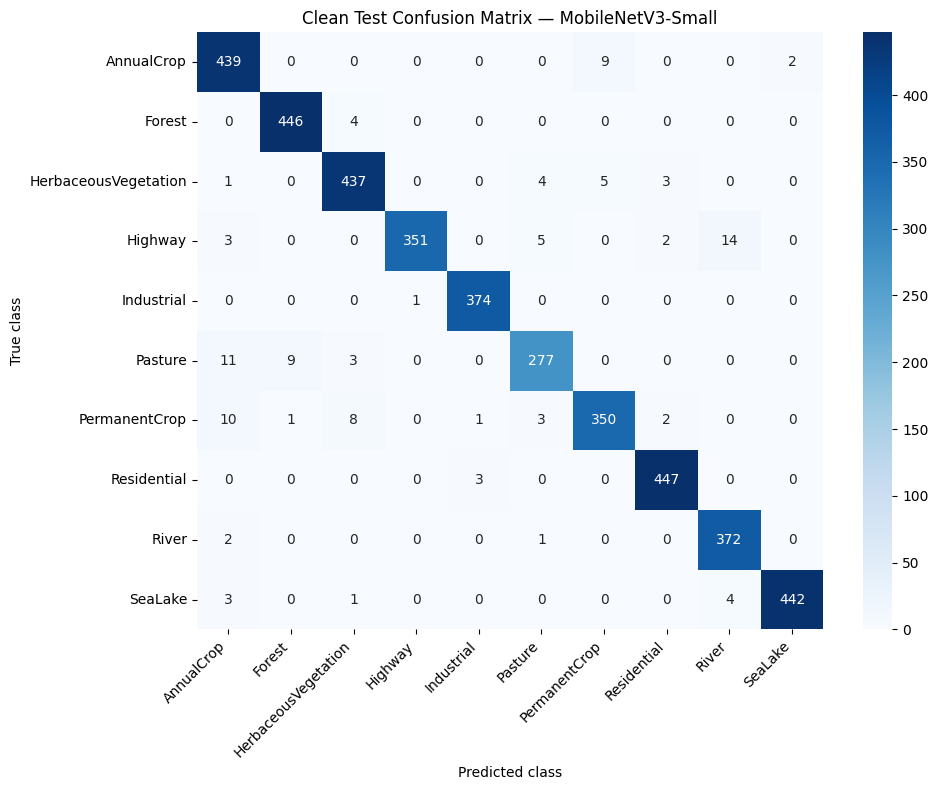


CLEAN TEST RESULTS: MobileViT-XXS
accuracy: 0.9598
macro_precision: 0.9615
macro_recall: 0.9569
macro_f1: 0.9581

Classification report:
                      precision    recall  f1-score   support

          AnnualCrop     0.9395    0.9667    0.9529       450
              Forest     0.9978    0.9889    0.9933       450
HerbaceousVegetation     0.8858    0.9822    0.9315       450
             Highway     0.9671    0.9413    0.9541       375
          Industrial     0.9602    0.9653    0.9628       375
             Pasture     0.9532    0.9500    0.9516       300
       PermanentCrop     0.9904    0.8240    0.8996       375
         Residential     0.9889    0.9933    0.9911       450
               River     0.9599    0.9573    0.9586       375
             SeaLake     0.9719    1.0000    0.9858       450

            accuracy                         0.9598      4050
           macro avg     0.9615    0.9569    0.9581      4050
        weighted avg     0.9612    0.9598    0.9594   

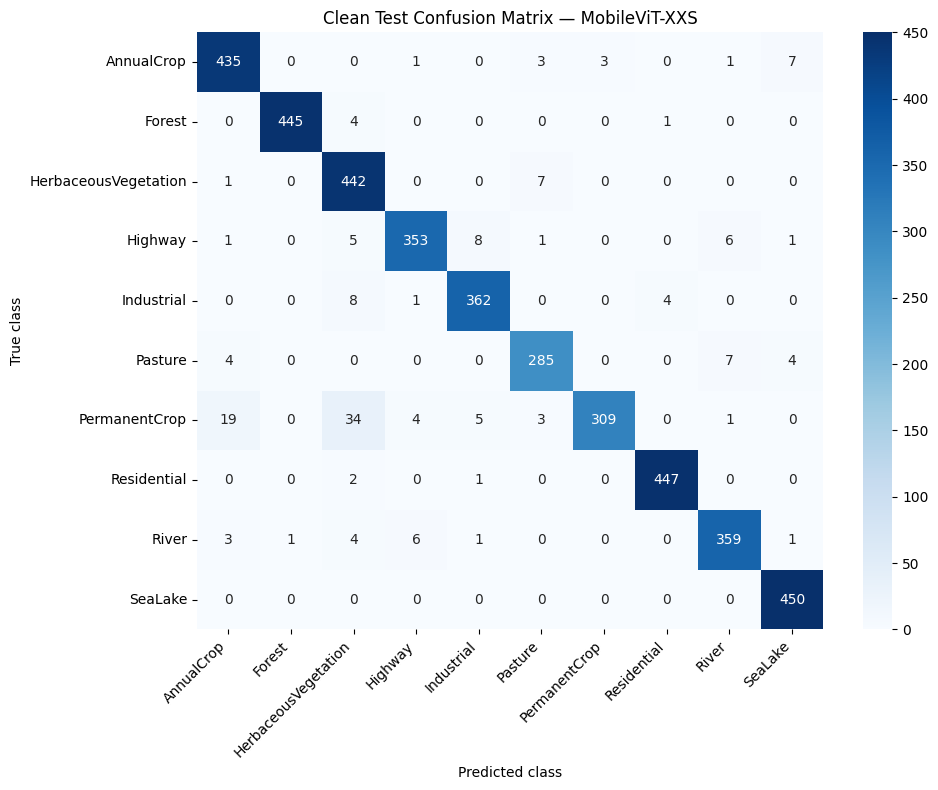


CLEAN TEST COMPARISON
            model  accuracy  macro_precision  macro_recall  macro_f1
MobileNetV3-Small    0.9716           0.9716        0.9695    0.9703
    MobileViT-XXS    0.9598           0.9615        0.9569    0.9581

Metrics saved to: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/clean_test_metrics.csv


In [ ]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

CLASS_NAMES = dataset.classes
test_results = []
clean_predictions = {}

def evaluate_clean_model(model, model_name):
    model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)

            predictions = outputs.argmax(dim=1).cpu().numpy()
            all_predictions.extend(predictions)
            all_labels.extend(labels.numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }

    clean_predictions[model_name] = {
        "y_true": y_true,
        "y_pred": y_pred,
    }

    print("\n" + "=" * 70)
    print(f"CLEAN TEST RESULTS: {model_name}")
    print("=" * 70)
    for key, value in metrics.items():
        if key != "model":
            print(f"{key}: {value:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    ))

    # Save confusion matrix figure
    cm = confusion_matrix(
        y_true, y_pred, labels=np.arange(len(CLASS_NAMES))
    )

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
    )
    plt.title(f"Clean Test Confusion Matrix — {model_name}")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    safe_name = model_name.lower().replace("-", "_").replace(" ", "_")
    figure_path = os.path.join(
        DRIVE_OUTPUT_DIR, f"{safe_name}_clean_confusion_matrix.png"
    )
    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    # Save raw confusion matrix
    cm_path = os.path.join(
        DRIVE_OUTPUT_DIR, f"{safe_name}_clean_confusion_matrix.csv"
    )
    pd.DataFrame(
        cm, index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(cm_path)

    return metrics


mobilenet_test_metrics = evaluate_clean_model(
    mobilenet_model, "MobileNetV3-Small"
)
mobilevit_test_metrics = evaluate_clean_model(
    mobilevit_model, "MobileViT-XXS"
)

test_results = [mobilenet_test_metrics, mobilevit_test_metrics]
test_metrics_df = pd.DataFrame(test_results)

metrics_path = os.path.join(
    DRIVE_OUTPUT_DIR, "clean_test_metrics.csv"
)
test_metrics_df.to_csv(metrics_path, index=False)

print("\n" + "=" * 70)
print("CLEAN TEST COMPARISON")
print("=" * 70)
print(test_metrics_df.round(4).to_string(index=False))
print(f"\nMetrics saved to: {metrics_path}")


As we can see from the above outputs, MobileNetV3-Small (97.1% accuracy) has a greater accuracy than MobileViT-XXS (95.9% accuracy).

## Controlled Image Corruptions
Now for the main part of the project, we will apply 3 different types of controlled corruptions (Gaussian noise, salt-and-pepper noise, rotation corruptions), at 3 different level of severity, before the RGB images are resized and normalized.

Corruption configurations:
{'corruption': 'gaussian_noise', 'severity': 1, 'sigma': 10}
{'corruption': 'gaussian_noise', 'severity': 2, 'sigma': 25}
{'corruption': 'gaussian_noise', 'severity': 3, 'sigma': 50}
{'corruption': 'salt_pepper', 'severity': 1, 'amount': 0.01}
{'corruption': 'salt_pepper', 'severity': 2, 'amount': 0.03}
{'corruption': 'salt_pepper', 'severity': 3, 'amount': 0.06}
{'corruption': 'rotation', 'severity': 1, 'degrees': 5}
{'corruption': 'rotation', 'severity': 2, 'degrees': 15}
{'corruption': 'rotation', 'severity': 3, 'degrees': 30}


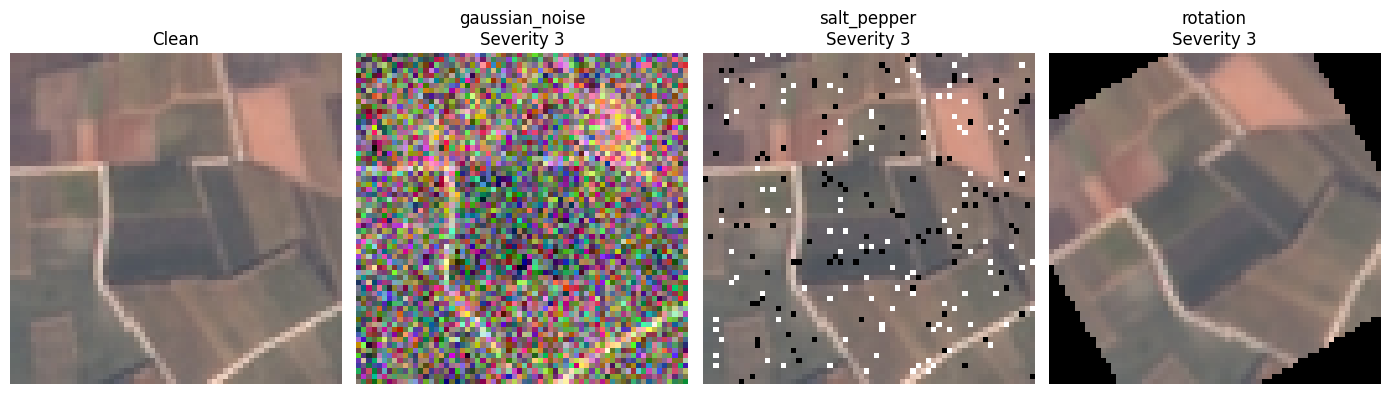


Preview saved to: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/corruption_examples.png
Corruption setup complete.


In [ ]:

from PIL import Image
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch
import os

CORRUPTION_CONFIGS = [
    {"corruption": "gaussian_noise", "severity": 1, "sigma": 10},
    {"corruption": "gaussian_noise", "severity": 2, "sigma": 25},
    {"corruption": "gaussian_noise", "severity": 3, "sigma": 50},
    {"corruption": "salt_pepper", "severity": 1, "amount": 0.01},
    {"corruption": "salt_pepper", "severity": 2, "amount": 0.03},
    {"corruption": "salt_pepper", "severity": 3, "amount": 0.06},
    {"corruption": "rotation", "severity": 1, "degrees": 5},
    {"corruption": "rotation", "severity": 2, "degrees": 15},
    {"corruption": "rotation", "severity": 3, "degrees": 30},
]

class CorruptedEuroSATTest(Dataset):
    def __init__(self, base_dataset, indices, corruption_config, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.config = corruption_config
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        original_index = self.indices[item]
        image_path, label = self.base_dataset.samples[original_index]

        with Image.open(image_path) as image_file:
            image = image_file.convert("RGB")

        config = self.config
        rng = np.random.default_rng(SEED + original_index)

        if config["corruption"] == "gaussian_noise":
            image_array = np.asarray(image, dtype=np.float32)
            noise = rng.normal(
                loc=0.0,
                scale=config["sigma"],
                size=image_array.shape,
            )
            corrupted_array = np.clip(
                image_array + noise, 0, 255
            ).astype(np.uint8)
            image = Image.fromarray(corrupted_array)

        elif config["corruption"] == "salt_pepper":
            image_array = np.asarray(image).copy()
            height, width, _ = image_array.shape
            total_pixels = height * width
            number_each = int(total_pixels * config["amount"] / 2)

            flat = image_array.reshape(-1, 3)
            salt_indices = rng.choice(
                total_pixels, size=number_each, replace=False
            )
            remaining = np.setdiff1d(
                np.arange(total_pixels), salt_indices,
                assume_unique=True,
            )
            pepper_count = min(number_each, len(remaining))
            pepper_indices = rng.choice(
                remaining, size=pepper_count, replace=False
            )

            flat[salt_indices] = 255
            flat[pepper_indices] = 0
            image = Image.fromarray(
                flat.reshape(height, width, 3)
            )

        elif config["corruption"] == "rotation":
            image = image.rotate(
                config["degrees"],
                resample=Image.Resampling.BILINEAR,
                expand=False,
                fillcolor=(0, 0, 0),
            )

        else:
            raise ValueError(
                f"Unknown corruption: {config['corruption']}"
            )

        if self.transform is not None:
            image = self.transform(image)

        return image, label


print("Corruption configurations:")
for config in CORRUPTION_CONFIGS:
    print(config)

# Inspect one example from each corruption type/severity
import matplotlib.pyplot as plt

sample_index = test_indices[0]
image_path, _ = dataset.samples[sample_index]

with Image.open(image_path) as image_file:
    original_image = image_file.convert("RGB")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(original_image)
axes[0].set_title("Clean")

for ax, config in zip(axes[1:], [
    CORRUPTION_CONFIGS[2],
    CORRUPTION_CONFIGS[5],
    CORRUPTION_CONFIGS[8],
]):
    preview_dataset = CorruptedEuroSATTest(
        dataset, [sample_index], config, transform=None
    )
    corrupted_image, _ = preview_dataset[0]
    ax.imshow(corrupted_image)
    ax.set_title(
        f"{config['corruption']}\nSeverity {config['severity']}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
preview_path = os.path.join(
    DRIVE_OUTPUT_DIR, "corruption_examples.png"
)
plt.savefig(preview_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nPreview saved to: {preview_path}")
print("Corruption setup complete.")


As seen above, we can see a sample image under the affects of the highest severity of Gaussian noise, salt-and-pepper noise, and rotation corruptions.

## Testing the Models Against the Corrupted Images
The models will be run against the corrupted images, annd their outputs will be compared with the results from the clean image testing to compute degradation.

In [ ]:

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
import pandas as pd
import numpy as np
import os
import torch
import time

def evaluate_corrupted_model(model, loader):
    model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)

            all_predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            all_labels.extend(labels.numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }


# Include clean test metrics as the severity-0 baseline
robustness_records = []

for model_name, metrics in [
    ("MobileNetV3-Small", mobilenet_test_metrics),
    ("MobileViT-XXS", mobilevit_test_metrics),
]:
    robustness_records.append({
        "model": model_name,
        "corruption": "clean",
        "severity": 0,
        "accuracy": metrics["accuracy"],
        "macro_precision": metrics["macro_precision"],
        "macro_recall": metrics["macro_recall"],
        "macro_f1": metrics["macro_f1"],
        "accuracy_drop": 0.0,
    })

models_to_evaluate = [
    ("MobileNetV3-Small", mobilenet_model),
    ("MobileViT-XXS", mobilevit_model),
]

total_start = time.perf_counter()

for config_number, config in enumerate(CORRUPTION_CONFIGS, start=1):
    print(
        f"\nCondition {config_number}/{len(CORRUPTION_CONFIGS)}: "
        f"{config['corruption']}, severity {config['severity']}"
    )

    corrupted_dataset = CorruptedEuroSATTest(
        base_dataset=dataset,
        indices=test_indices,
        corruption_config=config,
        transform=base_transform,
    )

    corrupted_loader = DataLoader(
        corrupted_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    for model_name, model in models_to_evaluate:
        metrics = evaluate_corrupted_model(model, corrupted_loader)

        clean_accuracy = next(
            item["accuracy"]
            for item in test_results
            if item["model"] == model_name
        )

        record = {
            "model": model_name,
            "corruption": config["corruption"],
            "severity": config["severity"],
            **metrics,
            "accuracy_drop": clean_accuracy - metrics["accuracy"],
        }
        robustness_records.append(record)

        print(
            f"  {model_name}: "
            f"accuracy={metrics['accuracy']:.4f}, "
            f"macro-F1={metrics['macro_f1']:.4f}, "
            f"accuracy drop={record['accuracy_drop']:.4f}"
        )

    del corrupted_loader, corrupted_dataset
    torch.cuda.empty_cache()

robustness_df = pd.DataFrame(robustness_records)

# Save complete table
robustness_csv = os.path.join(
    DRIVE_OUTPUT_DIR, "corruption_robustness_results.csv"
)
robustness_df.to_csv(robustness_csv, index=False)

# Save a compact accuracy table for quick comparison
accuracy_table = robustness_df.pivot_table(
    index=["corruption", "severity"],
    columns="model",
    values="accuracy",
).reset_index()

accuracy_csv = os.path.join(
    DRIVE_OUTPUT_DIR, "corruption_accuracy_comparison.csv"
)
accuracy_table.to_csv(accuracy_csv, index=False)

elapsed_minutes = (time.perf_counter() - total_start) / 60

print("\n" + "=" * 70)
print("CORRUPTION ROBUSTNESS RESULTS")
print("=" * 70)
print(
    robustness_df[
        ["model", "corruption", "severity", "accuracy",
         "macro_f1", "accuracy_drop"]
    ].round(4).to_string(index=False)
)
print(f"\nElapsed time: {elapsed_minutes:.2f} minutes")
print(f"Full results saved to: {robustness_csv}")
print(f"Accuracy comparison saved to: {accuracy_csv}")



Condition 1/9: gaussian_noise, severity 1
  MobileNetV3-Small: accuracy=0.1464, macro-F1=0.0826, accuracy drop=0.8252
  MobileViT-XXS: accuracy=0.1427, macro-F1=0.0764, accuracy drop=0.8170

Condition 2/9: gaussian_noise, severity 2
  MobileNetV3-Small: accuracy=0.1111, macro-F1=0.0200, accuracy drop=0.8605
  MobileViT-XXS: accuracy=0.1111, macro-F1=0.0200, accuracy drop=0.8486

Condition 3/9: gaussian_noise, severity 3
  MobileNetV3-Small: accuracy=0.1111, macro-F1=0.0200, accuracy drop=0.8605
  MobileViT-XXS: accuracy=0.1111, macro-F1=0.0200, accuracy drop=0.8486

Condition 4/9: salt_pepper, severity 1
  MobileNetV3-Small: accuracy=0.7442, macro-F1=0.7336, accuracy drop=0.2274
  MobileViT-XXS: accuracy=0.7316, macro-F1=0.7217, accuracy drop=0.2281

Condition 5/9: salt_pepper, severity 2
  MobileNetV3-Small: accuracy=0.5207, macro-F1=0.4550, accuracy drop=0.4509
  MobileViT-XXS: accuracy=0.3933, macro-F1=0.3222, accuracy drop=0.5664

Condition 6/9: salt_pepper, severity 3
  MobileNet

Inference gained from the above outputs:
- Gaussian noise causes the most degradation - Accuracy falls to 14.64% for MobileNetV3-Small and 14.27% for MobileViT-XXS, even though the severity was just level 1. Both models fall to 11.12% accuracy at severity levels 2 and 3.
- MobileNetV3-Small does better for salt-and-pepper noise - MobileNetV3-Small achieves 38.52% accuracy and MobileViT-XXS gets 27.21%, at the highest severity level.
- MobileViT-XXS does better against rotation - MobileViT-XXS gets 80.25% accuracy, while MobileNetV3-Small gets 69.06%.

## Gaussian Noise Sanity Check
Making sure the gaussian-noise implementation is correct, since the affects of even severity level 1 was significantly severe.

In [ ]:

from collections import Counter
import numpy as np
import torch
from torch.utils.data import DataLoader

# Compare the first clean test batch with a zero-noise corruption wrapper
clean_config = {
    "corruption": "gaussian_noise",
    "severity": 0,
    "sigma": 0,
}

diagnostic_dataset = CorruptedEuroSATTest(
    base_dataset=dataset,
    indices=test_indices,
    corruption_config=clean_config,
    transform=base_transform,
)

diagnostic_loader = DataLoader(
    diagnostic_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

clean_images, clean_labels = next(iter(test_loader))
wrapper_images, wrapper_labels = next(iter(diagnostic_loader))

print("=" * 70)
print("CLEAN PREPROCESSING CONSISTENCY CHECK")
print("=" * 70)
print("Labels identical:", torch.equal(clean_labels, wrapper_labels))
print(
    "Maximum absolute tensor difference:",
    (clean_images - wrapper_images).abs().max().item()
)
print(
    "Mean absolute tensor difference:",
    (clean_images - wrapper_images).abs().mean().item()
)

print("\n" + "=" * 70)
print("GAUSSIAN NOISE PIXEL STATISTICS")
print("=" * 70)

for config in CORRUPTION_CONFIGS:
    if config["corruption"] != "gaussian_noise":
        continue

    example_dataset = CorruptedEuroSATTest(
        base_dataset=dataset,
        indices=[test_indices[0]],
        corruption_config=config,
        transform=None,
    )
    corrupted_image, _ = example_dataset[0]
    array = np.asarray(corrupted_image)

    print(
        f"Severity {config['severity']} (sigma={config['sigma']}): "
        f"min={array.min()}, max={array.max()}, "
        f"mean={array.mean():.2f}, std={array.std():.2f}"
    )

print("\n" + "=" * 70)
print("PREDICTION DISTRIBUTION CHECK")
print("=" * 70)

# Compare clean and Gaussian severity-1 prediction counts
gaussian1_dataset = CorruptedEuroSATTest(
    base_dataset=dataset,
    indices=test_indices,
    corruption_config=CORRUPTION_CONFIGS[0],
    transform=base_transform,
)
gaussian1_loader = DataLoader(
    gaussian1_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

for model_name, model in models_to_evaluate:
    model.eval()
    clean_preds = []
    noisy_preds = []

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(DEVICE)
            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)
            clean_preds.extend(outputs.argmax(1).cpu().tolist())

        for images, _ in gaussian1_loader:
            images = images.to(DEVICE)
            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)
            noisy_preds.extend(outputs.argmax(1).cpu().tolist())

    print(f"\n{model_name}")
    print("Clean predictions per class:", dict(sorted(Counter(clean_preds).items())))
    print("Gaussian severity-1 predictions per class:", dict(sorted(Counter(noisy_preds).items())))

del diagnostic_dataset, diagnostic_loader
del gaussian1_dataset, gaussian1_loader
torch.cuda.empty_cache()


CLEAN PREPROCESSING CONSISTENCY CHECK
Labels identical: True
Maximum absolute tensor difference: 0.0
Mean absolute tensor difference: 0.0

GAUSSIAN NOISE PIXEL STATISTICS
Severity 1 (sigma=10): min=55, max=248, mean=118.97, std=25.25
Severity 2 (sigma=25): min=10, max=255, mean=119.12, std=34.02
Severity 3 (sigma=50): min=0, max=255, mean=119.47, std=53.84

PREDICTION DISTRIBUTION CHECK

MobileNetV3-Small
Clean predictions per class: {0: 469, 1: 456, 2: 453, 3: 352, 4: 378, 5: 290, 6: 364, 7: 454, 8: 390, 9: 444}
Gaussian severity-1 predictions per class: {0: 7, 1: 51, 3: 21, 4: 104, 7: 3860, 8: 7}

MobileViT-XXS
Clean predictions per class: {0: 463, 1: 446, 2: 499, 3: 365, 4: 377, 5: 299, 6: 312, 7: 452, 8: 374, 9: 463}
Gaussian severity-1 predictions per class: {0: 45, 2: 1, 3: 11, 4: 75, 7: 3918}


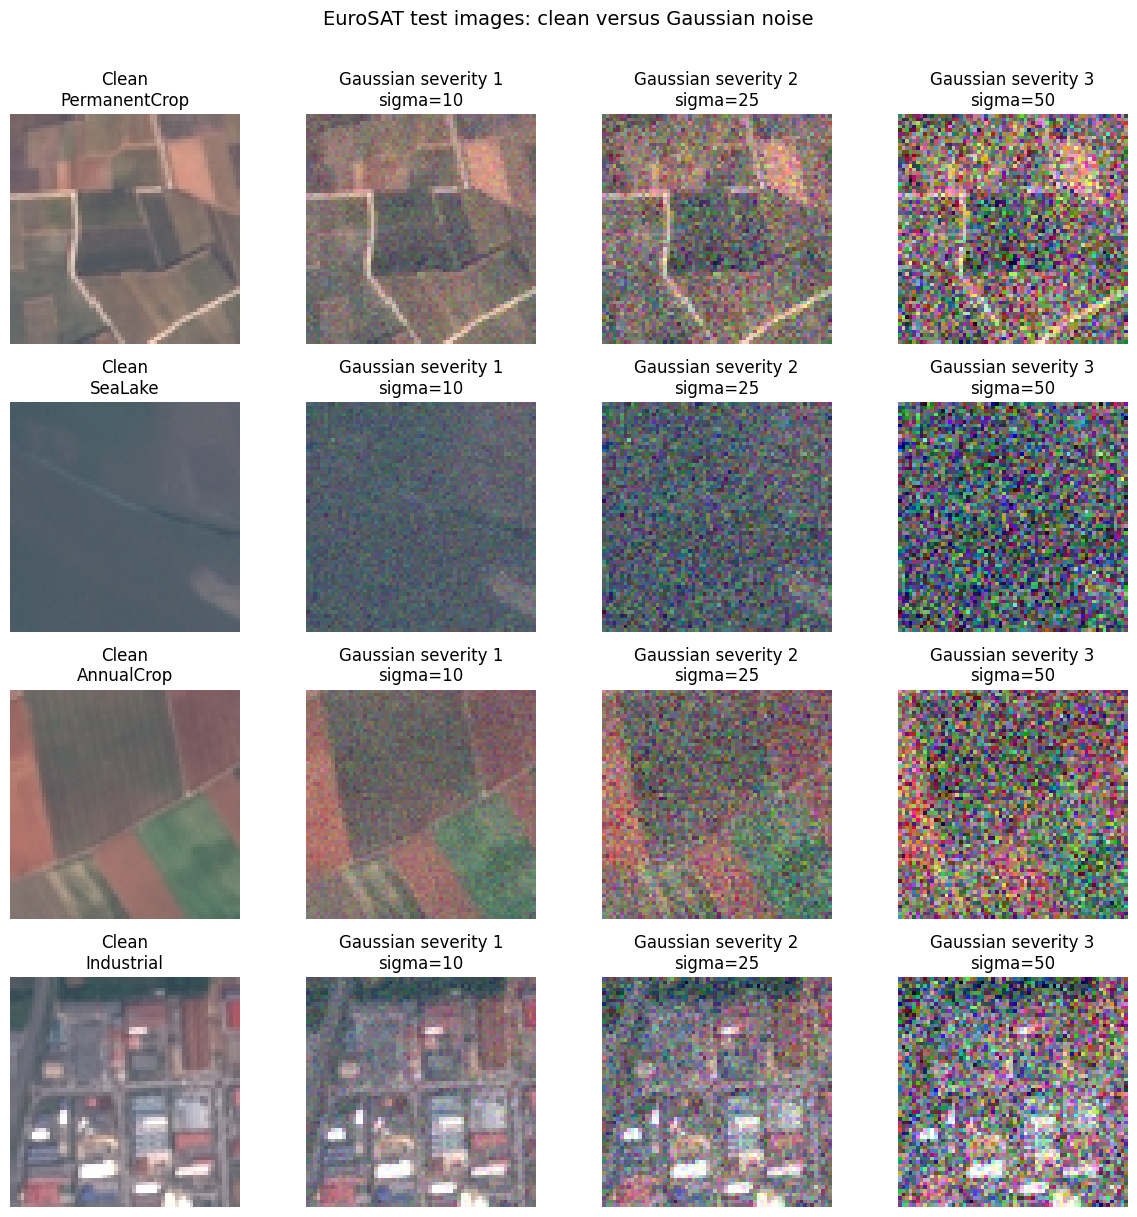

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Use four fixed examples from the held-out test set
example_indices = test_indices[:4]

gaussian_configs = [
    c for c in CORRUPTION_CONFIGS
    if c["corruption"] == "gaussian_noise"
]
gaussian_configs = sorted(gaussian_configs, key=lambda c: c["severity"])

fig, axes = plt.subplots(
    len(example_indices), 1 + len(gaussian_configs),
    figsize=(12, 3 * len(example_indices))
)

for row, original_index in enumerate(example_indices):
    image_path, label = dataset.samples[int(original_index)]
    clean_image = Image.open(image_path).convert("RGB")

    # Clean image
    axes[row, 0].imshow(clean_image)
    axes[row, 0].set_title(f"Clean\n{dataset.classes[label]}")
    axes[row, 0].axis("off")

    # Corrupted versions of the same image
    for col, config in enumerate(gaussian_configs, start=1):
        example_dataset = CorruptedEuroSATTest(
            base_dataset=dataset,
            indices=[int(original_index)],
            corruption_config=config,
            transform=None,
        )
        noisy_image, _ = example_dataset[0]

        axes[row, col].imshow(noisy_image)
        axes[row, col].set_title(
            f"Gaussian severity {config['severity']}\n"
            f"sigma={config['sigma']}"
        )
        axes[row, col].axis("off")

plt.suptitle(
    "EuroSAT test images: clean versus Gaussian noise",
    fontsize=14,
    y=1.01,
)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from PIL import Image

print("Gaussian noise magnitude check")
print("=" * 65)

for config in gaussian_configs:
    original_index = int(test_indices[0])

    image_path, _ = dataset.samples[original_index]
    clean = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float32
    )

    example_dataset = CorruptedEuroSATTest(
        base_dataset=dataset,
        indices=[original_index],
        corruption_config=config,
        transform=None,
    )
    corrupted_image, _ = example_dataset[0]
    corrupted = np.asarray(corrupted_image, dtype=np.float32)

    difference = corrupted - clean
    rmse = np.sqrt(np.mean(difference ** 2))
    psnr = 20 * np.log10(255.0 / max(rmse, 1e-12))

    print(
        f"Severity {config['severity']} | "
        f"configured sigma={config['sigma']} | "
        f"measured RMSE={rmse:.2f} | "
        f"PSNR={psnr:.2f} dB"
    )

print("\nInterpretation:")
print("- RMSE estimates the average pixel-level change.")
print("- Higher PSNR means less distortion.")
print("- Clipping at pixel values 0 and 255 can make measured RMSE")
print("  differ from the configured sigma.")

Gaussian noise magnitude check
Severity 1 | configured sigma=10 | measured RMSE=9.97 | PSNR=28.16 dB
Severity 2 | configured sigma=25 | measured RMSE=24.89 | PSNR=20.21 dB
Severity 3 | configured sigma=50 | measured RMSE=48.86 | PSNR=14.35 dB

Interpretation:
- RMSE estimates the average pixel-level change.
- Higher PSNR means less distortion.
- Clipping at pixel values 0 and 255 can make measured RMSE
  differ from the configured sigma.


## Plotting Results
Now, we plot the results we got from running the models against the corrupted images.

Corruption results columns: ['model', 'corruption', 'severity', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'accuracy_drop']
Clean metrics columns: ['model', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1']

Corruption labels found: ['clean', 'gaussian_noise', 'salt_pepper', 'rotation']
Models found: ['MobileNetV3-Small', 'MobileViT-XXS']


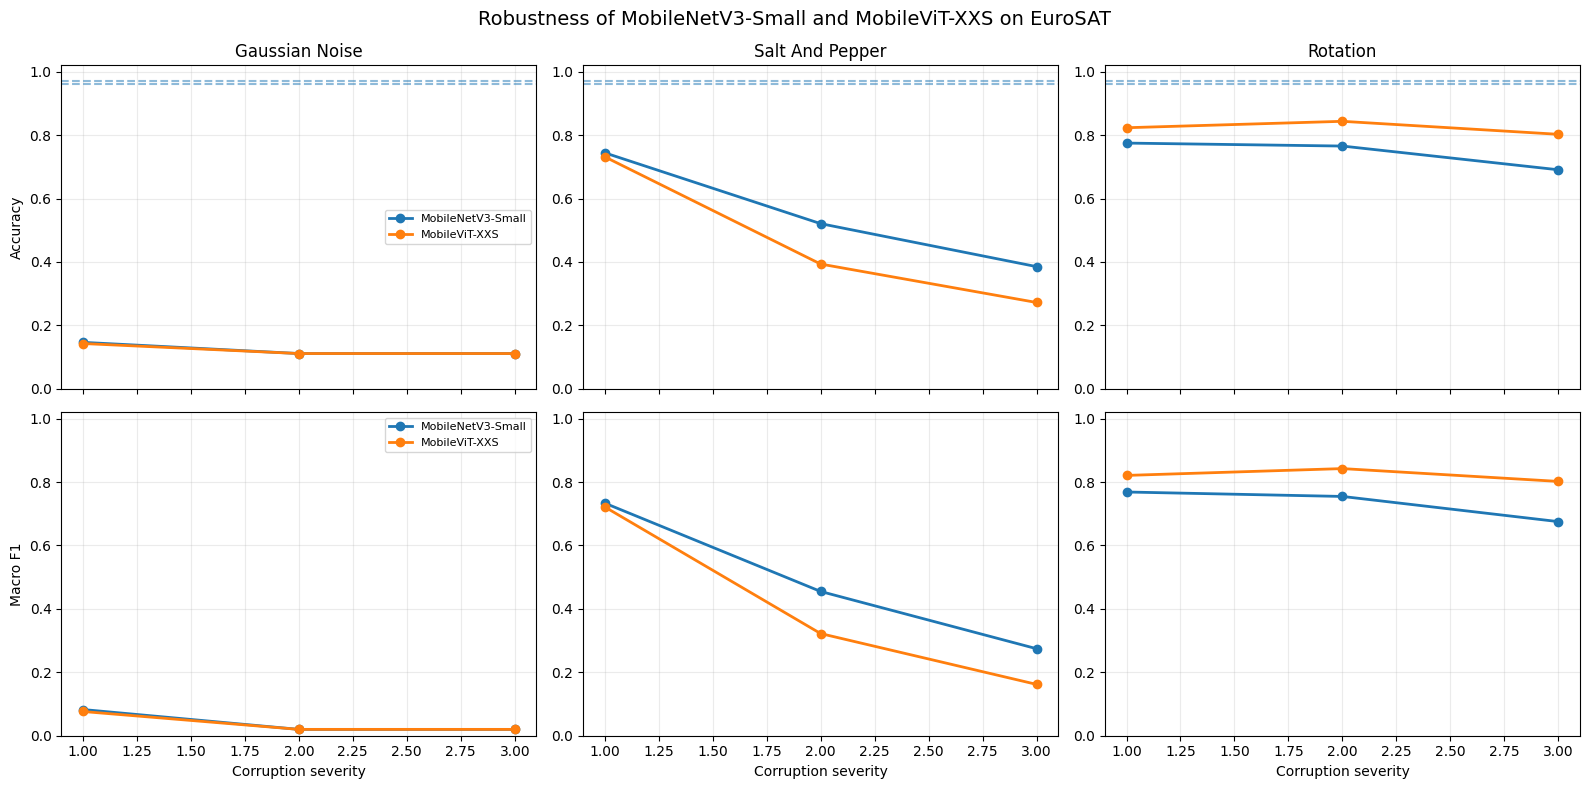


Saved figure: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/robustness_accuracy_f1_plots.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

results_path = os.path.join(
    DRIVE_OUTPUT_DIR, "corruption_robustness_results.csv"
)
clean_path = os.path.join(
    DRIVE_OUTPUT_DIR, "clean_test_metrics.csv"
)

results_df = pd.read_csv(results_path)
clean_df = pd.read_csv(clean_path)

print("Corruption results columns:", results_df.columns.tolist())
print("Clean metrics columns:", clean_df.columns.tolist())

# Standardise column names for easier matching
results_df.columns = [
    c.strip().lower().replace(" ", "_") for c in results_df.columns
]
clean_df.columns = [
    c.strip().lower().replace(" ", "_") for c in clean_df.columns
]

def find_column(df, candidates):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    raise ValueError(
        f"Could not find any of {candidates}. "
        f"Available columns: {df.columns.tolist()}"
    )

model_col = find_column(results_df, ["model", "model_name"])
corruption_col = find_column(
    results_df, ["corruption", "corruption_type"]
)
severity_col = find_column(results_df, ["severity", "level"])
accuracy_col = find_column(results_df, ["accuracy", "test_accuracy"])
f1_col = find_column(
    results_df, ["macro_f1", "f1_macro", "macro_f1_score"]
)

clean_model_col = find_column(clean_df, ["model", "model_name"])
clean_accuracy_col = find_column(
    clean_df, ["accuracy", "test_accuracy"]
)

# Clean baseline accuracies for the horizontal reference lines
clean_accuracy = dict(
    zip(clean_df[clean_model_col], clean_df[clean_accuracy_col])
)

corruption_order = [
    "gaussian_noise",
    "salt_and_pepper",
    "rotation",
]

# Match common alternative labels if the CSV uses display names
available_corruptions = results_df[corruption_col].unique().tolist()
print("\nCorruption labels found:", available_corruptions)
print("Models found:", results_df[model_col].unique().tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex="col")

for col, corruption in enumerate(corruption_order):
    subset = results_df[
        results_df[corruption_col].astype(str).str.lower() == corruption
    ].copy()

    # Fall back to a partial match if labels differ slightly
    if subset.empty:
        subset = results_df[
            results_df[corruption_col].astype(str).str.lower()
            .str.contains(corruption.replace("_", "|"), regex=True)
        ].copy()

    if subset.empty:
        axes[0, col].set_visible(False)
        axes[1, col].set_visible(False)
        print(f"Skipping plot: no rows matched {corruption}")
        continue

    for model_name, model_rows in subset.groupby(model_col):
        model_rows = model_rows.sort_values(severity_col)

        axes[0, col].plot(
            model_rows[severity_col],
            model_rows[accuracy_col],
            marker="o",
            linewidth=2,
            label=str(model_name),
        )
        axes[1, col].plot(
            model_rows[severity_col],
            model_rows[f1_col],
            marker="o",
            linewidth=2,
            label=str(model_name),
        )

        if model_name in clean_accuracy:
            axes[0, col].axhline(
                clean_accuracy[model_name],
                linestyle="--",
                alpha=0.5,
            )

    axes[0, col].set_title(corruption.replace("_", " ").title())
    axes[0, col].set_ylabel("Accuracy" if col == 0 else "")
    axes[1, col].set_ylabel("Macro F1" if col == 0 else "")
    axes[1, col].set_xlabel("Corruption severity")
    axes[0, col].set_ylim(0, 1.02)
    axes[1, col].set_ylim(0, 1.02)

    for row in range(2):
        axes[row, col].grid(True, alpha=0.25)

axes[0, 0].legend(fontsize=8, loc="best")
axes[1, 0].legend(fontsize=8, loc="best")
fig.suptitle(
    "Robustness of MobileNetV3-Small and MobileViT-XXS on EuroSAT",
    fontsize=14,
)
plt.tight_layout()

figure_path = os.path.join(
    DRIVE_OUTPUT_DIR, "robustness_accuracy_f1_plots.png"
)
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved figure:", figure_path)

## Overall Results Across Corrupted Image Runs



In [ ]:
import os
import pandas as pd

results_path = os.path.join(
    DRIVE_OUTPUT_DIR, "corruption_robustness_results.csv"
)
clean_path = os.path.join(
    DRIVE_OUTPUT_DIR, "clean_test_metrics.csv"
)

results_df = pd.read_csv(results_path)
clean_df = pd.read_csv(clean_path)

# Exclude the clean baseline when averaging corrupted performance
corrupted_df = results_df[
    results_df["corruption"] != "clean"
].copy()

summary_df = (
    corrupted_df
    .groupby(["model", "corruption"])
    .agg(
        mean_accuracy=("accuracy", "mean"),
        mean_macro_f1=("macro_f1", "mean"),
        mean_accuracy_drop=("accuracy_drop", "mean"),
        worst_accuracy=("accuracy", "min"),
        best_accuracy=("accuracy", "max"),
    )
    .reset_index()
)

# Add clean accuracy and the average accuracy across all corruption conditions
clean_baseline = clean_df[["model", "accuracy"]].rename(
    columns={"accuracy": "clean_accuracy"}
)

summary_df = summary_df.merge(clean_baseline, on="model", how="left")
summary_df["mean_accuracy"] = summary_df["mean_accuracy"].round(4)
summary_df["mean_macro_f1"] = summary_df["mean_macro_f1"].round(4)
summary_df["mean_accuracy_drop"] = summary_df["mean_accuracy_drop"].round(4)
summary_df["worst_accuracy"] = summary_df["worst_accuracy"].round(4)
summary_df["best_accuracy"] = summary_df["best_accuracy"].round(4)
summary_df["clean_accuracy"] = summary_df["clean_accuracy"].round(4)

summary_path = os.path.join(
    DRIVE_OUTPUT_DIR, "robustness_summary_by_corruption.csv"
)
summary_df.to_csv(summary_path, index=False)

print("Mean performance across severity levels (higher is better):")
display(summary_df)

# Overall mean across all 9 corrupted conditions per model
overall_df = (
    corrupted_df.groupby("model")
    .agg(
        mean_corrupted_accuracy=("accuracy", "mean"),
        mean_corrupted_macro_f1=("macro_f1", "mean"),
        mean_accuracy_drop=("accuracy_drop", "mean"),
    )
    .reset_index()
    .round(4)
)

print("\nOverall average across all 9 corrupted conditions:")
display(overall_df)

overall_path = os.path.join(
    DRIVE_OUTPUT_DIR, "robustness_overall_summary.csv"
)
overall_df.to_csv(overall_path, index=False)

print("\nSaved:")
print(summary_path)
print(overall_path)

Mean performance across severity levels (higher is better):


,model,corruption,mean_accuracy,mean_macro_f1,mean_accuracy_drop,worst_accuracy,best_accuracy,clean_accuracy
0,MobileNetV3-Small,gaussian_noise,0.1229,0.0409,0.8487,0.1111,0.1464,0.9716
1,MobileNetV3-Small,rotation,0.7436,0.7328,0.2280,0.6906,0.7748,0.9716
2,MobileNetV3-Small,salt_pepper,0.5500,0.4876,0.4216,0.3852,0.7442,0.9716
3,MobileViT-XXS,gaussian_noise,0.1216,0.0388,0.8381,0.1111,0.1427,0.9598
4,MobileViT-XXS,rotation,0.8230,0.8218,0.1367,0.8025,0.8435,0.9598
5,MobileViT-XXS,salt_pepper,0.4657,0.4019,0.4941,0.2721,0.7316,0.9598



Overall average across all 9 corrupted conditions:


,model,mean_corrupted_accuracy,mean_corrupted_macro_f1,mean_accuracy_drop
0,MobileNetV3-Small,0.4722,0.4204,0.4994
1,MobileViT-XXS,0.4701,0.4208,0.4896



Saved:
/content/drive/MyDrive/EuroSAT_Robustness_Efficiency/robustness_summary_by_corruption.csv
/content/drive/MyDrive/EuroSAT_Robustness_Efficiency/robustness_overall_summary.csv


The very low Gaussian-noise scores, affect the overall averages in the above summary. This makes the per-class metrics more reliable.

- We can see that both models severely suffer when running the Gaussian-noise images (~12% mean accuracy).
- MobileNetV3-Small performs better on average (55.00%) against salt-and-pepper noise.
- MobileViT-XXS does better on average (82.30%) against rotational corruption.

## Measuring Models Efficiency
Considering the parameter count, saved checkpoint size, inference latency, and throughput on the L4 GPU to get the efficiency metrics.

In [ ]:
import os
import time
import pandas as pd
import torch

# Best checkpoints saved during training
checkpoint_paths = {
    "MobileNetV3-Small": os.path.join(
        DRIVE_OUTPUT_DIR, "checkpoints",
        "mobilenet_v3_small_best.pth"
    ),
    "MobileViT-XXS": os.path.join(
        DRIVE_OUTPUT_DIR, "checkpoints",
        "mobilevit_xxs_best.pth"
    ),
}

# Use one fixed batch from the test loader for fair timing
benchmark_images, _ = next(iter(test_loader))
benchmark_images = benchmark_images.to(DEVICE)
single_image = benchmark_images[:1]

def benchmark_inference(model, inputs, warmup=20, iterations=100):
    model.eval()

    # Warm-up GPU kernels and synchronize timing
    with torch.inference_mode():
        for _ in range(warmup):
            with torch.amp.autocast("cuda", dtype=torch.float16):
                _ = model(inputs)

    torch.cuda.synchronize()

    start = time.perf_counter()
    with torch.inference_mode():
        for _ in range(iterations):
            with torch.amp.autocast("cuda", dtype=torch.float16):
                _ = model(inputs)

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    avg_batch_latency_ms = elapsed / iterations * 1000
    throughput = inputs.shape[0] / (elapsed / iterations)

    return avg_batch_latency_ms, throughput

efficiency_rows = []

for model_name, model in models_to_evaluate:
    print(f"Benchmarking {model_name}...")

    parameter_count = sum(p.numel() for p in model.parameters())
    trainable_parameters = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    checkpoint_path = checkpoint_paths[model_name]
    checkpoint_size_mb = os.path.getsize(checkpoint_path) / (1024 ** 2)

    # Batch-size-1 latency
    latency_1_ms, throughput_1 = benchmark_inference(
        model, single_image
    )

    # Batch-size-64 latency and throughput
    latency_64_ms, throughput_64 = benchmark_inference(
        model, benchmark_images
    )

    efficiency_rows.append({
        "model": model_name,
        "parameters": parameter_count,
        "trainable_parameters": trainable_parameters,
        "checkpoint_size_mb": round(checkpoint_size_mb, 3),
        "batch1_latency_ms": round(latency_1_ms, 3),
        "batch1_images_per_second": round(throughput_1, 2),
        "batch64_latency_ms": round(latency_64_ms, 3),
        "batch64_images_per_second": round(throughput_64, 2),
    })

    print(
        f"  Parameters: {parameter_count:,} | "
        f"Checkpoint: {checkpoint_size_mb:.2f} MB"
    )
    print(
        f"  Batch 1: {latency_1_ms:.3f} ms/image, "
        f"{throughput_1:.2f} images/sec"
    )
    print(
        f"  Batch 64: {latency_64_ms:.3f} ms/batch, "
        f"{throughput_64:.2f} images/sec"
    )

efficiency_df = pd.DataFrame(efficiency_rows)

efficiency_path = os.path.join(
    DRIVE_OUTPUT_DIR, "model_efficiency_metrics.csv"
)
efficiency_df.to_csv(efficiency_path, index=False)

print("\nEfficiency comparison:")
display(efficiency_df)
print("Saved:", efficiency_path)
print("Benchmark device:", torch.cuda.get_device_name(0))

Benchmarking MobileNetV3-Small...
  Parameters: 1,528,106 | Checkpoint: 5.95 MB
  Batch 1: 7.759 ms/image, 128.88 images/sec
  Batch 64: 7.470 ms/batch, 8567.29 images/sec
Benchmarking MobileViT-XXS...
  Parameters: 954,234 | Checkpoint: 3.75 MB
  Batch 1: 12.384 ms/image, 80.75 images/sec
  Batch 64: 15.343 ms/batch, 4171.38 images/sec

Efficiency comparison:


,model,parameters,trainable_parameters,checkpoint_size_mb,batch1_latency_ms,batch1_images_per_second,batch64_latency_ms,batch64_images_per_second
0,MobileNetV3-Small,1528106,1528106,5.950,7.759,128.88,7.470,8567.29
1,MobileViT-XXS,954234,954234,3.751,12.384,80.75,15.343,4171.38


Saved: /content/drive/MyDrive/EuroSAT_Robustness_Efficiency/model_efficiency_metrics.csv
Benchmark device: NVIDIA L4


In this benxchmark, we can see that:
- MobileViT-XXS has fewer parameters
- MobileViT-XXS has a smaller checkpoint
- MobileNetV3-Small is faster

## Final Comparison Table

In [ ]:
import os
import pandas as pd

def read_project_csv(filename):
    path = os.path.join(DRIVE_OUTPUT_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing expected file: {path}")
    return pd.read_csv(path)

clean = read_project_csv("clean_test_metrics.csv")
robust = read_project_csv("robustness_overall_summary.csv")
efficiency = read_project_csv("model_efficiency_metrics.csv")
training = read_project_csv("training_summary.csv")

# Keep only columns needed for the final comparison
clean = clean[["model", "accuracy", "macro_f1"]].rename(columns={
    "accuracy": "clean_test_accuracy",
    "macro_f1": "clean_test_macro_f1",
})

robust = robust.rename(columns={
    "mean_corrupted_accuracy": "mean_corrupted_accuracy",
    "mean_corrupted_macro_f1": "mean_corrupted_macro_f1",
})

efficiency_cols = [
    "model",
    "parameters",
    "checkpoint_size_mb",
    "batch1_latency_ms",
    "batch1_images_per_second",
    "batch64_images_per_second",
]
efficiency = efficiency[efficiency_cols]

final_comparison = (
    clean
    .merge(robust, on="model", how="left")
    .merge(efficiency, on="model", how="left")
)

# Display rounded values without changing the stored precision
numeric_cols = final_comparison.select_dtypes(
    include="number"
).columns
final_display = final_comparison.copy()
final_display[numeric_cols] = final_display[numeric_cols].round(4)

print("FINAL MODEL COMPARISON")
display(final_display)

comparison_path = os.path.join(
    DRIVE_OUTPUT_DIR, "final_model_comparison.csv"
)
final_comparison.to_csv(comparison_path, index=False)

print("\nTraining summary:")
display(training)

print("\nSaved final comparison to:")
print(comparison_path)

FINAL MODEL COMPARISON


,model,clean_test_accuracy,clean_test_macro_f1,mean_corrupted_accuracy,mean_corrupted_macro_f1,mean_accuracy_drop,parameters,checkpoint_size_mb,batch1_latency_ms,batch1_images_per_second,batch64_images_per_second
0,MobileNetV3-Small,0.9716,0.9703,0.4722,0.4204,0.4994,1528106,5.950,7.759,128.88,8567.29
1,MobileViT-XXS,0.9598,0.9581,0.4701,0.4208,0.4896,954234,3.751,12.384,80.75,4171.38



Training summary:


,model,best_epoch,best_val_accuracy,training_minutes,checkpoint
0,MobileNetV3-Small,3,0.972840,2.473345,/content/drive/MyDrive/EuroSAT_Robustness_Effi...
1,MobileViT-XXS,4,0.962963,2.432370,/content/drive/MyDrive/EuroSAT_Robustness_Effi...



Saved final comparison to:
/content/drive/MyDrive/EuroSAT_Robustness_Efficiency/final_model_comparison.csv


## Verify All Outputs
Making sure that all the outputs are present in the directory, after running all the processes in this notebook.

In [ ]:
import os
import pandas as pd

project_dir = DRIVE_OUTPUT_DIR

required_files = [
    "eurosat_class_distribution.csv",
    "eurosat_split_distribution.csv",
    "eurosat_split_indices.npz",
    "split_metadata.json",
    "dataset_summary.json",
    "training_config.json",
    "training_summary.csv",
    "clean_test_metrics.csv",
    "corruption_robustness_results.csv",
    "corruption_accuracy_comparison.csv",
    "robustness_summary_by_corruption.csv",
    "robustness_overall_summary.csv",
    "model_efficiency_metrics.csv",
    "final_model_comparison.csv",
    "robustness_accuracy_f1_plots.png",
    "corruption_examples.png",
]

required_checkpoints = [
    "checkpoints/mobilenet_v3_small_best.pth",
    "checkpoints/mobilevit_xxs_best.pth",
]

all_required = required_files + required_checkpoints
audit_rows = []

for relative_path in all_required:
    full_path = os.path.join(project_dir, relative_path)
    exists = os.path.isfile(full_path)
    size_mb = os.path.getsize(full_path) / (1024 ** 2) if exists else None

    audit_rows.append({
        "file": relative_path,
        "exists": exists,
        "size_mb": round(size_mb, 3) if size_mb is not None else None,
    })

audit_df = pd.DataFrame(audit_rows)

print("PROJECT ARTIFACT AUDIT")
display(audit_df)

missing = audit_df.loc[~audit_df["exists"], "file"].tolist()

print(f"\nFiles checked: {len(all_required)}")
print(f"Present: {len(all_required) - len(missing)}")
print(f"Missing: {len(missing)}")

if missing:
    print("\nMissing files to investigate:")
    for filename in missing:
        print(" -", filename)
else:
    print("\nAll expected files are present.")

# List every file currently in the project folder, including subfolders
print("\nFULL PROJECT FILE LIST")
for root, dirs, files in os.walk(project_dir):
    for filename in sorted(files):
        full_path = os.path.join(root, filename)
        relative_path = os.path.relpath(full_path, project_dir)
        print(f"{relative_path} ({os.path.getsize(full_path) / (1024 ** 2):.2f} MB)")

PROJECT ARTIFACT AUDIT


,file,exists,size_mb
0,eurosat_class_distribution.csv,True,0.000
1,eurosat_split_distribution.csv,True,0.000
2,eurosat_split_indices.npz,True,0.207
3,split_metadata.json,True,0.000
4,dataset_summary.json,True,0.001
5,training_config.json,True,0.000
6,training_summary.csv,True,0.000
7,clean_test_metrics.csv,True,0.000
8,corruption_robustness_results.csv,True,0.002
9,corruption_accuracy_comparison.csv,True,0.001



Files checked: 18
Present: 18
Missing: 0

All expected files are present.

FULL PROJECT FILE LIST
clean_test_metrics.csv (0.00 MB)
corruption_accuracy_comparison.csv (0.00 MB)
corruption_examples.png (0.08 MB)
corruption_robustness_results.csv (0.00 MB)
dataset_summary.json (0.00 MB)
eurosat_class_distribution.csv (0.00 MB)
eurosat_split_distribution.csv (0.00 MB)
eurosat_split_indices.npz (0.21 MB)
final_model_comparison.csv (0.00 MB)
mobilenet_v3_small_best_history.csv (0.00 MB)
mobilenetv3_small_clean_confusion_matrix.csv (0.00 MB)
mobilenetv3_small_clean_confusion_matrix.png (0.17 MB)
mobilevit_xxs_best_history.csv (0.00 MB)
mobilevit_xxs_clean_confusion_matrix.csv (0.00 MB)
mobilevit_xxs_clean_confusion_matrix.png (0.18 MB)
model_efficiency_metrics.csv (0.00 MB)
robustness_accuracy_f1_plots.png (0.21 MB)
robustness_overall_summary.csv (0.00 MB)
robustness_summary_by_corruption.csv (0.00 MB)
split_metadata.json (0.00 MB)
training_config.json (0.00 MB)
training_summary.csv (0.00 MB